# Recommender system: ranking charts and content-based recommendations (TMDB 5000)
**Business question.** A streaming service (or any catalogue business) wants a credible "top picks" chart and a "because you watched X" list for every title.

**Data.** 4,803 films from The Movie Database (TMDB 5000): overview, genres, keywords, top-billed cast, director, votes.

**Approach.**
1. **Charts:** rank by a Bayesian **weighted rating** rather than the raw average, so a film with three 10/10 votes does not top the chart.
2. **Content-based recommendations:** cosine similarity on (a) TF-IDF of plot overviews, (b) a metadata "soup" of genres, cast and director, and (c) a blend of the two.
3. **Offline evaluation without user data:** keywords are **held out** from every model. A model is judged by how many TMDB keywords its top-10 recommendations share with the query film, against random and popularity baselines.
4. **Hybrid re-ranking:** trade relevance off against quality using the weighted rating.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
m = pd.read_csv("data/tmdb_5000_movies_slim.csv.gz").fillna({"overview": "", "genres": "", "keywords": "", "cast_top5": "", "director": ""})
m["year"] = pd.to_datetime(m["release_date"], errors="coerce").dt.year
print(m.shape)
m[["title", "year", "genres", "director", "vote_average", "vote_count"]].head()

(4803, 16)


,title,year,genres,director,vote_average,vote_count
0,Avatar,2009.0,Action|Adventure|Fantasy|Science Fiction,James Cameron,7.2,11800
1,Pirates of the Caribbean: At World's End,2007.0,Adventure|Fantasy|Action,Gore Verbinski,6.9,4500
2,Spectre,2015.0,Action|Adventure|Crime,Sam Mendes,6.3,4466
3,The Dark Knight Rises,2012.0,Action|Crime|Drama|Thriller,Christopher Nolan,7.6,9106
4,John Carter,2012.0,Action|Adventure|Science Fiction,Andrew Stanton,6.1,2124


## 1. A chart that is robust to small samples
IMDB-style weighted rating: $WR=\frac{v}{v+m}R+\frac{m}{v+m}C$, where $R$ is the film's mean vote, $v$ its vote count, $C$ the catalogue mean and $m$ the minimum votes required (here the 90th percentile of vote counts).

In [2]:
C = m.vote_average.mean(); mv = m.vote_count.quantile(0.90)
m["wr"] = (m.vote_count / (m.vote_count + mv)) * m.vote_average + (mv / (m.vote_count + mv)) * C
print(f"C = {C:.2f}, m = {mv:.0f} votes")
raw_top = m[m.vote_count > 0].nlargest(5, "vote_average")[["title", "vote_average", "vote_count"]]
wr_top = m.nlargest(10, "wr")[["title", "year", "vote_average", "vote_count", "wr"]]
print("Top 5 by raw average (note the tiny vote counts):"); display(raw_top)
print("Top 10 by weighted rating:"); wr_top

C = 6.09, m = 1838 votes
Top 5 by raw average (note the tiny vote counts):


,title,vote_average,vote_count
3519,Stiff Upper Lips,10.0,1
4045,"Dancer, Texas Pop. 81",10.0,1
4247,Me You and Five Bucks,10.0,2
4662,Little Big Top,10.0,1
3992,Sardaarji,9.5,2


Top 10 by weighted rating:


,title,year,vote_average,vote_count,wr
1881,The Shawshank Redemption,1994.0,8.5,8205,8.059
662,Fight Club,1999.0,8.3,9413,7.939
65,The Dark Knight,2008.0,8.2,12002,7.920
3232,Pulp Fiction,1994.0,8.3,8428,7.905
96,Inception,2010.0,8.1,13752,7.863
3337,The Godfather,1972.0,8.4,5893,7.851
95,Interstellar,2014.0,8.1,10867,7.809
809,Forrest Gump,1994.0,8.2,7927,7.803
329,The Lord of the Rings: The Return of the King,2003.0,8.1,8064,7.727
1990,The Empire Strikes Back,1980.0,8.2,5879,7.698


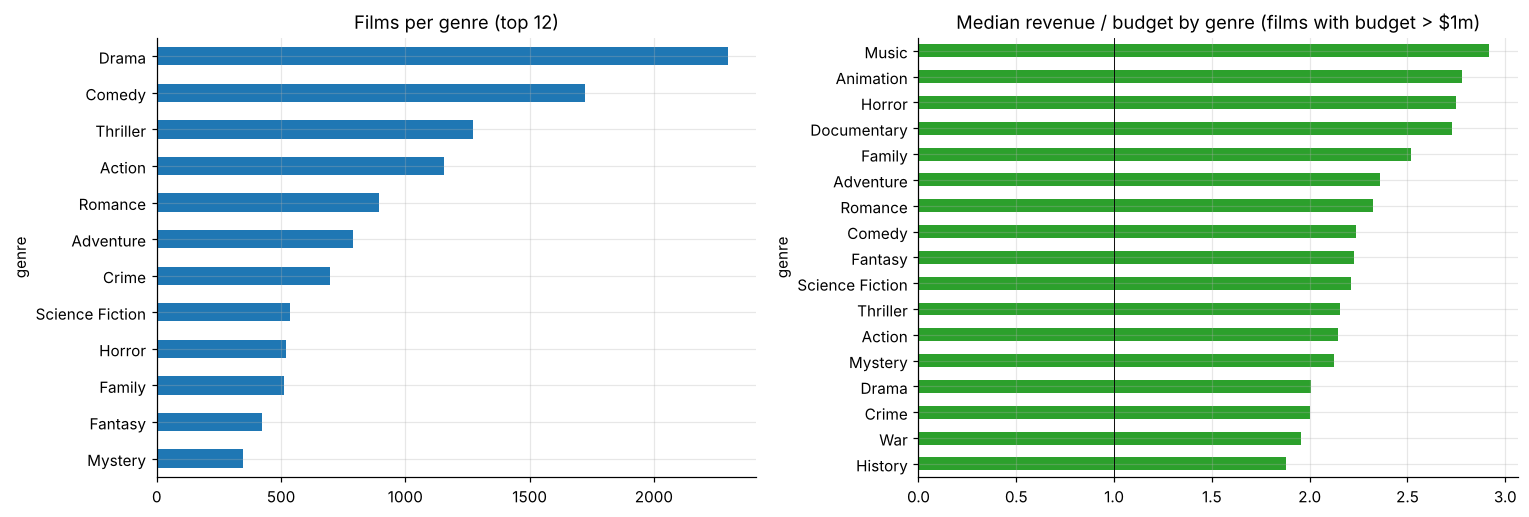

,films,mean_rating,mean_wr,median_revenue_to_budget
genre,,,,
Drama,2297,6.39,6.21,2.01
Comedy,1722,5.95,6.13,2.24
Thriller,1274,6.01,6.17,2.15
Action,1154,5.99,6.17,2.14
Romance,894,6.21,6.17,2.32
Adventure,790,6.16,6.22,2.36
Crime,696,6.27,6.22,2.00
Science Fiction,535,6.01,6.21,2.21
Horror,519,5.63,6.10,2.75


In [3]:
genres = m.genres.str.split("|").explode().replace("", np.nan).dropna()
g = m.assign(genre=m.genres.str.split("|")).explode("genre")
g = g[g.genre != ""]
stats = g.groupby("genre").agg(films=("title", "size"), mean_rating=("vote_average", "mean"),
                               median_roi=("revenue", lambda s: np.nan), mean_wr=("wr", "mean")).sort_values("films", ascending=False)
roi = g[(g.budget > 1e6) & (g.revenue > 0)].assign(roi=lambda d: d.revenue / d.budget).groupby("genre")["roi"].median()
stats["median_revenue_to_budget"] = roi; stats = stats.drop(columns="median_roi")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
stats["films"].head(12).plot.barh(ax=axes[0], title="Films per genre (top 12)"); axes[0].invert_yaxis()
s = stats[stats.films >= 100].sort_values("median_revenue_to_budget")
s["median_revenue_to_budget"].plot.barh(ax=axes[1], color="C2", title="Median revenue / budget by genre (films with budget > $1m)")
axes[1].axvline(1, c="k", lw=.6)
plt.tight_layout(); plt.savefig(IMG / "genres.png", bbox_inches="tight"); plt.show()
stats.round(2).head(12)

## 2. Content-based similarity
Keywords are deliberately **not** used to build any model; they are kept for evaluation.

In [4]:
tf = TfidfVectorizer(stop_words="english", min_df=2, ngram_range=(1, 2), sublinear_tf=True)
S_plot = cosine_similarity(tf.fit_transform(m.overview))
tok = lambda s: [x.replace(" ", "").lower() for x in s.split("|") if x]
soup = (m.genres.apply(tok) + m.cast_top5.apply(lambda s: tok(s)[:3]) + m.director.apply(lambda s: tok(s) * 2)).str.join(" ")
S_meta = cosine_similarity(CountVectorizer().fit_transform(soup))
S_blend = 0.5 * S_plot + 0.5 * S_meta
for S in (S_plot, S_meta, S_blend): np.fill_diagonal(S, -1)
idx = pd.Series(m.index, index=m.title.str.lower()).groupby(level=0).first()

def recommend(title, S=S_blend, k=10, quality=0.0):
    i = idx[title.lower()]
    score = S[i] + quality * (m.wr.values - m.wr.mean()) / m.wr.std() * S[i].std()
    top = np.argsort(-score)[:k]
    return m.iloc[top][["title", "year", "genres", "director", "wr"]].assign(similarity=S[i][top].round(3))
recommend("The Dark Knight")

,title,year,genres,director,wr,similarity
3,The Dark Knight Rises,2012.0,Action|Crime|Drama|Thriller,Christopher Nolan,7.347,0.561
119,Batman Begins,2005.0,Action|Crime|Drama,Christopher Nolan,7.219,0.435
1196,The Prestige,2006.0,Drama|Mystery|Thriller,Christopher Nolan,7.437,0.334
1033,Insomnia,2002.0,Crime|Mystery|Thriller,Christopher Nolan,6.364,0.286
4638,Amidst the Devil's Wings,2014.0,Drama|Action|Crime,,6.092,0.261
96,Inception,2010.0,Action|Thriller|Science Fiction|Mystery|Adventure,Christopher Nolan,7.863,0.251
4099,Harsh Times,2005.0,Crime|Drama|Thriller|Action,David Ayer,6.112,0.250
3573,Memento,2000.0,Mystery|Thriller,Christopher Nolan,7.471,0.238
95,Interstellar,2014.0,Adventure|Drama|Science Fiction,Christopher Nolan,7.809,0.238
299,Batman Forever,1995.0,Action|Crime|Fantasy,Joel Schumacher,5.692,0.223


In [5]:
recommend("Toy Story")

,title,year,genres,director,wr,similarity
343,Toy Story 2,1999.0,Animation|Comedy|Family,John Lasseter,6.907,0.666
42,Toy Story 3,2010.0,Animation|Family|Comedy,Lee Unkrich,7.169,0.448
40,Cars 2,2011.0,Animation|Family|Adventure|Comedy,John Lasseter,5.939,0.334
566,Cars,2006.0,Animation|Adventure|Comedy|Family,John Lasseter,6.437,0.334
837,Free Birds,2013.0,Animation|Comedy|Family,Jimmy Hayward,6.045,0.204
1612,Larry Crowne,2011.0,Comedy|Romance|Drama,Tom Hanks,6.028,0.190
231,"Monsters, Inc.",2001.0,Animation|Comedy|Family,Pete Docter,7.170,0.181
4010,That Thing You Do!,1996.0,Comedy|Drama,Tom Hanks,6.169,0.175
3670,Running Forever,2015.0,Family,,6.092,0.167
766,Garfield: A Tail of Two Kitties,2006.0,Animation|Comedy|Family,Tim Hill,5.892,0.160


In [6]:
# keyword-overlap evaluation on 600 query films that have keywords
kw = m.keywords.str.split("|").apply(lambda L: set(x for x in L if x))
rng = np.random.default_rng(0)
queries = rng.choice(np.where(kw.apply(len) >= 3)[0], 600, replace=False)
pop_top = np.argsort(-m.popularity.values)[:11]
def jacc(a, b): return len(a & b) / len(a | b) if a | b else 0.0
def evaluate(get_top):
    j, g = [], []
    for q in queries:
        top = get_top(q)
        j.append(np.mean([jacc(kw[q], kw[t]) for t in top]))
        gq = set(m.genres[q].split("|")); g.append(np.mean([len(gq & set(m.genres[t].split("|"))) > 0 for t in top]))
    return {"keyword Jaccard@10": np.mean(j), "share sharing a genre@10": np.mean(g)}
res = pd.DataFrame({
    "random": evaluate(lambda q: rng.choice(np.delete(np.arange(len(m)), q), 10, replace=False)),
    "most popular": evaluate(lambda q: [t for t in pop_top if t != q][:10]),
    "plot TF-IDF": evaluate(lambda q: np.argsort(-S_plot[q])[:10]),
    "metadata soup": evaluate(lambda q: np.argsort(-S_meta[q])[:10]),
    "blend 50/50": evaluate(lambda q: np.argsort(-S_blend[q])[:10]),
}).T
res["lift vs random"] = res["keyword Jaccard@10"] / res.loc["random", "keyword Jaccard@10"]
res

,keyword Jaccard@10,share sharing a genre@10,lift vs random
random,0.003,0.498,1.000
most popular,0.007,0.533,2.276
plot TF-IDF,0.016,0.665,5.339
metadata soup,0.012,0.942,4.081
blend 50/50,0.017,0.941,5.682


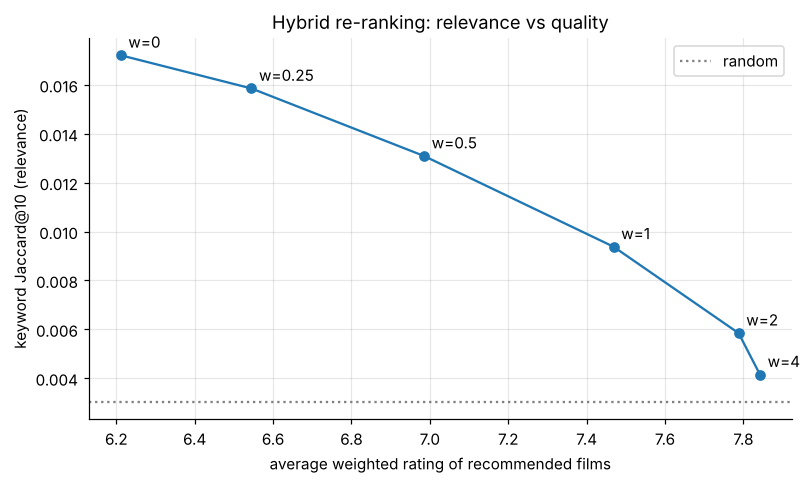

,keyword Jaccard@10,share sharing a genre@10,mean WR of recs
quality weight,,,
0.00,0.017,0.941,6.211
0.25,0.016,0.944,6.545
0.50,0.013,0.953,6.985
1.00,0.009,0.926,7.469
2.00,0.006,0.746,7.788
4.00,0.004,0.641,7.842


In [7]:
rows = []
for w in [0, 0.25, 0.5, 1, 2, 4]:
    def top(q, w=w):
        sc = S_blend[q] + w * (m.wr.values - m.wr.mean()) / m.wr.std() * S_blend[q].std()
        return np.argsort(-sc)[:10]
    r = evaluate(top); r["mean WR of recs"] = np.mean([m.wr.values[top(q)].mean() for q in queries]); r["quality weight"] = w
    rows.append(r)
tr = pd.DataFrame(rows).set_index("quality weight")
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(tr["mean WR of recs"], tr["keyword Jaccard@10"], "o-")
for w, r in tr.iterrows(): ax.annotate(f"w={w:g}", (r["mean WR of recs"], r["keyword Jaccard@10"]), xytext=(5, 5), textcoords="offset points")
ax.axhline(res.loc["random", "keyword Jaccard@10"], c="grey", ls=":", label="random")
ax.set_xlabel("average weighted rating of recommended films"); ax.set_ylabel("keyword Jaccard@10 (relevance)")
ax.set_title("Hybrid re-ranking: relevance vs quality"); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "relevance_quality.png", bbox_inches="tight"); plt.show()
tr.round(4)

## Findings
* **Raw averages make useless charts.** The five "best" films by mean vote have 1-2 votes each. The weighted rating (minimum 1,838 votes) gives a credible top 10, led by *The Shawshank Redemption*, *Fight Club* and *The Dark Knight*.
* **The blended content model is the most relevant.** On 600 query films, its top-10 lists share 5.7× more held-out keywords with the query than random picks. Plot TF-IDF alone reaches 5.3×, metadata alone 4.1× and "most popular" 2.3×. The metadata soup keeps 94% of recommendations within a shared genre, against 67% for plot text alone.
* **Sanity checks pass.** *The Dark Knight* returns *The Dark Knight Rises*, *Batman Begins* and other Nolan films; *Toy Story* returns its sequels and the *Cars* films.
* **Quality vs relevance is a dial, not a free lunch.** A small quality weight (w = 0.5) raises the average weighted rating of recommendations from 6.2 to 7.0 at the cost of about a quarter of keyword relevance (0.017 to 0.013). Beyond w = 1 the lists turn into a generic "best films" chart and genre consistency falls to 64-75%.
* **Genre economics:** horror, animation and music films show the highest median revenue/budget among genres with at least 100 films. Revenue is only available for released titles that reported it, so these ratios are optimistic.
* **What content-based models cannot do:** learn from what users actually watch. With viewing data, collaborative filtering (matrix factorisation) would be added and evaluated on held-out interactions.